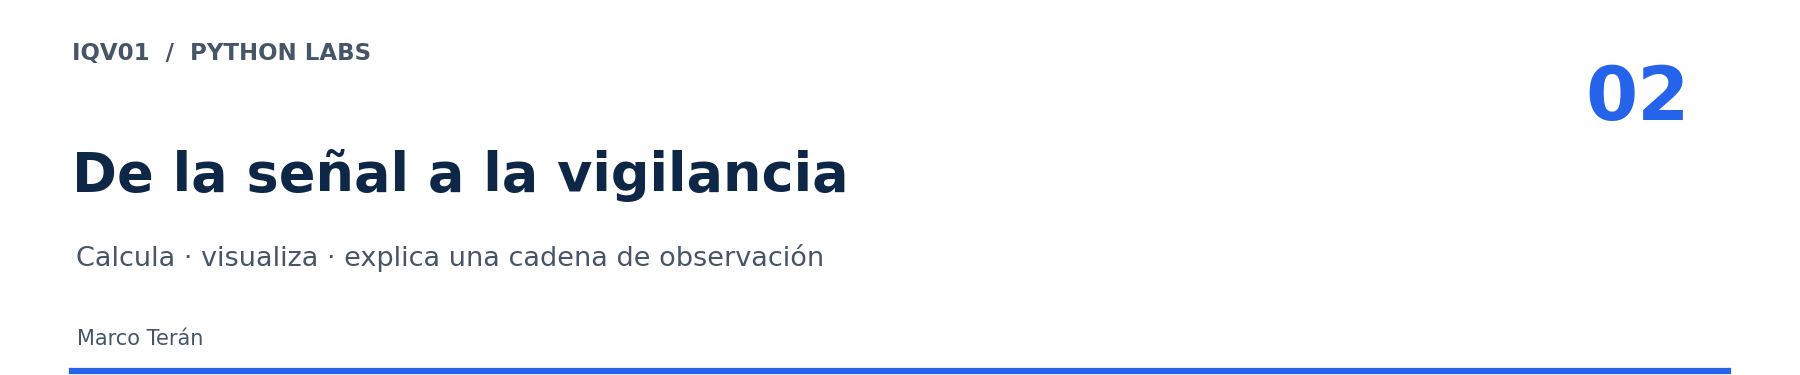

**Tu ruta:** observa un ejemplo → predice → ejecuta → completa → interpreta.

En Colab, guarda una copia en Drive. Ejecuta las celdas de arriba hacia abajo con ▶ o `Shift + Enter`.
En los ejercicios cambia `None` por tu expresión. `None` significa «todavía sin respuesta».
La respuesta esperada te ayuda a comprobar tu cálculo; conserva también las unidades.

Una torre recibe señales; un sistema de vigilancia produce observaciones con **tiempo, origen y calidad**.
Una potencia alta o un mensaje recibido no garantizan una posición correcta.

Trabajaremos con modelos y datos sintéticos. Cada resultado debe incluir su unidad y sus supuestos.
Usamos $c=3.00\times10^8$ m/s como aproximación didáctica.

Fenómeno: lo que ocurre; señal: magnitud observable; dato: representación registrada; información: interpretación con contexto. No son sinónimos.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

C = 3.00e8  # m/s
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 110, "axes.titleweight": "bold"})

def w_a_dbm(potencia_w):
    return 10 * np.log10(potencia_w / 1e-3)

def db_a_factor(valor_db):
    return 10 ** (valor_db / 10)

def mostrar(respuestas, esperado, etiquetas):
    """Comprueba varios números sin detener los ejercicios pendientes."""
    for nombre, valor, ref in zip(etiquetas, respuestas, esperado):
        if valor is None:
            print(f"{nombre}: pendiente")
        else:
            correcto = np.isclose(valor, ref, rtol=1e-4, atol=1e-9)
            print(f"{nombre}: {valor:.6g} | {'✓' if correcto else 'revisa'}")

## 1 · Unidades antes que fórmulas

| Prefijo | Factor | Ejemplo en SI |
|---|---:|---|
| p, n, µ, m | $10^{-12},10^{-9},10^{-6},10^{-3}$ | 100 ns = `100e-9` s |
| k, M, G | $10^3,10^6,10^9$ | 1090 MHz = `1090e6` Hz |

Una sección de 2.5 mm² vale `2.5e-6` m², porque se eleva al cuadrado el factor de longitud.
Un byte contiene 8 bits. `e` escribe notación científica en Python.

**dB** expresa una relación de potencias: $10\log_{10}(P_2/P_1)$.
**dBm** refiere a 1 mW; **dBW**, a 1 W. No sumes potencias en dBm: conviértelas a W primero.

In [2]:
potencia_w = 0.1
print(f"{potencia_w} W = {w_a_dbm(potencia_w):.1f} dBm")
print(f"Doble potencia: {10*np.log10(2):.2f} dB")
print(f"30 dBm = {1e-3 * db_a_factor(30):.1f} W")
print(f"30 dBm = {30-30} dBW")

0.1 W = 20.0 dBm
Doble potencia: 3.01 dB
30 dBm = 1.0 W
30 dBm = 0 dBW


## 2 · Alimentación: fuente → camino → carga

El voltaje es una diferencia entre dos puntos. La corriente es carga por tiempo: $I=\Delta Q/\Delta t$.
Para una resistencia óhmica: $V=IR$. La potencia es $P=VI$; la energía, $E=Pt$.

Un cable tiene $R=\rho L/A$. **L incluye ida y retorno**.
Con corriente constante: caída $IR$, pérdida $I^2R$. Una fuente correcta en vacío no prueba la tensión bajo carga.

In [3]:
rho = 1.68e-8  # ohm·m, valor supuesto para el ejemplo
longitud_total_m = 30
seccion_m2 = 2.5e-6
corriente_a = 3
r_cable = rho * longitud_total_m / seccion_m2
print(f"Cable: {r_cable:.4f} Ω")
print(f"Caída: {corriente_a*r_cable:.4f} V")
print(f"Pérdida: {corriente_a**2*r_cable:.4f} W")

Cable: 0.2016 Ω
Caída: 0.6048 V
Pérdida: 1.8144 W


Una batería de 24 V y 100 Ah almacena nominalmente 2400 Wh.
Si usamos 50% de esa energía y la eficiencia es 85%, quedan 1020 Wh útiles.
A 120 W constantes dura 8.5 h. Este modelo omite envejecimiento y variación de carga.

In [4]:
energia_util_wh = 24 * 100 * 0.50 * 0.85
print(f"Autonomía ideal ajustada: {energia_util_wh / 120:.1f} h")

Autonomía ideal ajustada: 8.5 h


## 3 · Señales: lo que cambia en el tiempo

Un seno sigue $x(t)=A\sin(2\pi ft+\phi)$: amplitud A, frecuencia f y fase φ en radianes.
$T=1/f$ y $\omega=2\pi f$. Para un seno puro: $V_{rms}=V_p/\sqrt2$; $V_{pp}=2V_p$.
DC/AC describe variación temporal; analógico/digital describe representación.

La FFT muestra componentes de frecuencia. Aquí graficamos **amplitud de un seno sintético**,
con muestreo uniforme, número entero de ciclos y sin calibración a dBm.

La fase positiva adelanta este seno: un desplazamiento de 90° a 50 Hz equivale a 5 ms. La fase temporal de una señal no es el ángulo espacial de una antena. Ancho de banda puede referirse a contenido de señal, paso de un sistema o banda equivalente de ruido: declara cuál usas.

RMS: 1.414 V


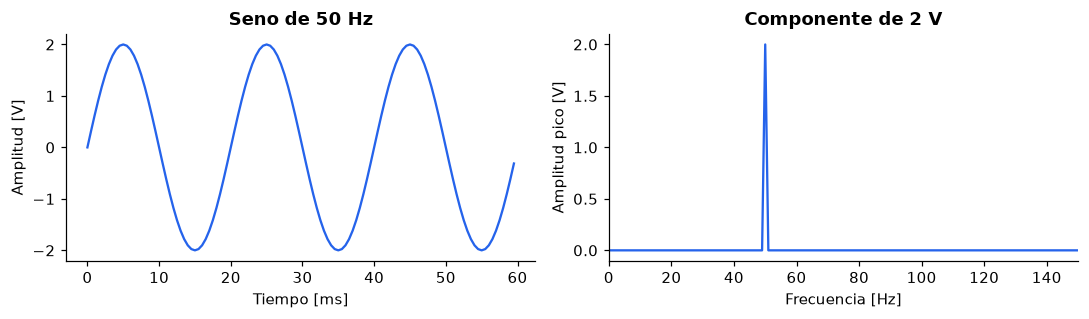

In [5]:
fs = 2000  # Hz
t = np.arange(2000) / fs
x = 2 * np.sin(2*np.pi*50*t)
frecuencias = np.fft.rfftfreq(len(x), 1/fs)
amplitud = np.abs(np.fft.rfft(x)) / len(x)
amplitud[1:-1] *= 2  # espectro unilateral; DC y Nyquist no se duplican
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(t[:120]*1e3, x[:120], color="#2563EB")
ax[0].set(xlabel="Tiempo [ms]", ylabel="Amplitud [V]", title="Seno de 50 Hz")
ax[1].plot(frecuencias, amplitud, color="#2563EB")
ax[1].set(xlim=(0, 150), xlabel="Frecuencia [Hz]", ylabel="Amplitud pico [V]", title="Componente de 2 V")
fig.tight_layout(); plt.show()
print(f"RMS: {np.sqrt(np.mean(x**2)):.3f} V")

Un pulso dura τ y se repite a PRF: $T_r=1/PRF$, $D=\tau\,PRF$ y $P_{med}=P_{pico}D$.
$B\sim1/\tau$ solo estima un orden de magnitud para un pulso rectangular.

A unos 290 K, el ruido térmico es $N_{dBm}\approx-174+10\log_{10}(B_{Hz})$.
La figura de ruido NF agrega degradación; una sensibilidad modelada es $N+NF+SNR_{min}$.
Duplicar B agrega unos 3 dB de ruido.

In [6]:
tau_s, prf_hz, pico_w = 1e-6, 2000, 50e3
print(f"Duty: {tau_s*prf_hz:.4f}; media: {pico_w*tau_s*prf_hz:.0f} W")
ruido_dbm = -174 + 10*np.log10(10e6)
print(f"Ruido en 10 MHz: {ruido_dbm:.1f} dBm")
print(f"Sensibilidad (NF=3, SNR mínimo=10): {ruido_dbm+3+10:.1f} dBm")

Duty: 0.0020; media: 100 W
Ruido en 10 MHz: -104.0 dBm
Sensibilidad (NF=3, SNR mínimo=10): -91.0 dBm


## 4 · Propagación: un enlace en un solo sentido

$\lambda=c/f$. En espacio libre y campo lejano:
$$FSPL_{dB}=20\log_{10}(4\pi d/\lambda),\qquad
P_r=P_tG_tG_r(\lambda/4\pi d)^2/L.$$
En dB sumamos ganancias y restamos pérdidas. El margen es recepción menos sensibilidad.
Esto modela un **enlace unidireccional**, como una transmisión cooperativa; el eco radar necesita otra ecuación.

En una onda EM, campos eléctrico y magnético varían juntos y transportan energía. La frecuencia se conserva al cambiar de medio en este modelo; velocidad y longitud de onda pueden cambiar.

In [7]:
f_hz, distancia_m = 1090e6, 200e3
onda_m = C / f_hz
fspl_db = 20*np.log10(4*np.pi*distancia_m/onda_m)
recibida_dbm = 50 + 3 + 8 - 2 - fspl_db
print(f"λ: {onda_m:.6f} m; FSPL: {fspl_db:.3f} dB")
print(f"Recepción: {recibida_dbm:.3f} dBm; margen: {recibida_dbm-(-91):.3f} dB")

λ: 0.275229 m; FSPL: 139.211 dB
Recepción: -80.211 dBm; margen: 10.789 dB


La línea de vista no asegura despeje de Fresnel. Para alturas en m, el horizonte radioeléctrico
estándar aproximado es $d_{km}=4.12(\sqrt{h_1}+\sqrt{h_2})$.
El primer radio de Fresnel es $r_1=\sqrt{\lambda d_1d_2/(d_1+d_2)}$ con distancias en m.
El 60% de despeje será una condición dada del ejercicio, no garantía universal.

In [8]:
horizonte_km = 4.12 * (np.sqrt(25) + np.sqrt(10000))
fresnel_m = np.sqrt(onda_m * 100e3 * 100e3 / 200e3)
print(f"Horizonte aproximado: {horizonte_km:.1f} km")
print(f"Fresnel en el centro: {fresnel_m:.3f} m; 60%: {0.6*fresnel_m:.3f} m")

Horizonte aproximado: 432.6 km
Fresnel en el centro: 117.309 m; 60%: 70.386 m


## 5 · Mira el haz: una antena calculada

Este **factor de arreglo** modela N elementos isotrópicos en línea, separados media longitud de onda,
con amplitudes iguales. Sumamos sus campos con las fases de cada dirección y elevamos el módulo al cuadrado.
Es un corte angular normalizado, **no la medición de una antena real**.

0 dB es el máximo relativo. Los máximos pequeños son lóbulos laterales; los mínimos son nulos.
Los elementos isotrópicos producen también un haz posterior: el modelo no incluye reflector.
Con separación fija, más elementos significan mayor apertura y un haz más estrecho.
El diagrama normalizado no entrega por sí solo la ganancia absoluta.

Broadside es la dirección perpendicular a la línea de elementos; aquí corresponde a 0°. Un patrón omnidireccional ideal no concentra azimut como este arreglo.

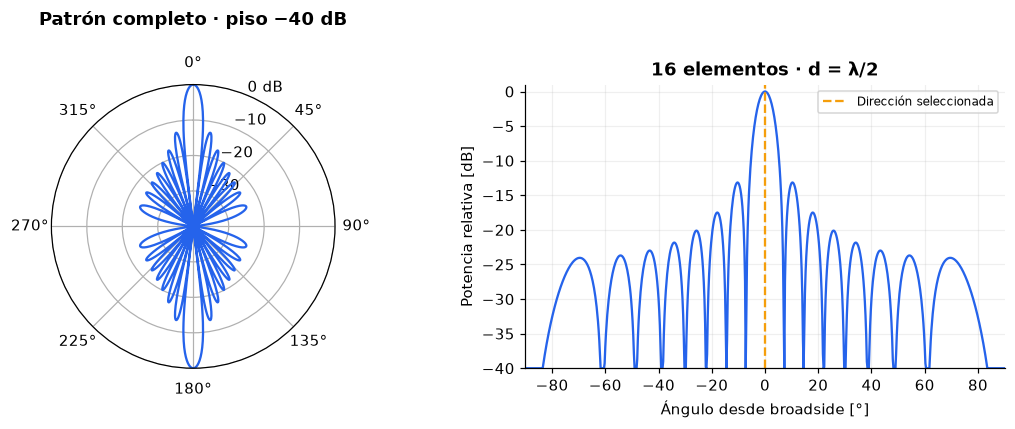

In [9]:
def patron_ula(theta_rad, elementos=16, direccion_deg=0):
    fase = np.pi * (np.sin(theta_rad) - np.sin(np.deg2rad(direccion_deg)))
    campo = np.mean(np.exp(1j*np.arange(elementos)[:, None]*fase[None, :]), axis=0)
    return np.abs(campo)**2

def dibujar_antena(elementos=16, direccion_deg=0):
    theta = np.linspace(-np.pi, np.pi, 1441)
    potencia = patron_ula(theta, elementos, direccion_deg)
    relativo_db = 10*np.log10(np.maximum(potencia, 1e-4))
    fig = plt.figure(figsize=(10, 4))
    polar = fig.add_subplot(121, projection="polar")
    polar.plot(theta, relativo_db+40, color="#2563EB")
    polar.set_theta_zero_location("N"); polar.set_theta_direction(-1)
    polar.set_ylim(0, 40); polar.set_yticks([10,20,30,40])
    polar.set_yticklabels(["−30", "−20", "−10", "0 dB"])
    polar.set_title("Patrón completo · piso −40 dB", pad=20)
    ax = fig.add_subplot(122)
    frontal = np.abs(theta) <= np.pi/2
    ax.plot(np.rad2deg(theta[frontal]), relativo_db[frontal], color="#2563EB")
    ax.axvline(direccion_deg, color="#F59E0B", linestyle="--", label="Dirección seleccionada")
    ax.set(xlabel="Ángulo desde broadside [°]", ylabel="Potencia relativa [dB]",
           ylim=(-40, 1), xlim=(-90,90), title=f"{elementos} elementos · d = λ/2")
    ax.grid(alpha=0.2); ax.legend(fontsize=8)
    fig.tight_layout(); plt.show()

dibujar_antena()

**Predice antes de mover:** ¿qué pasa con el ancho al pasar de 8 a 32 elementos?
¿Cambiar dirección crea potencia o redistribuye la respuesta?
Ejecuta la siguiente celda para activar controles. Si no aparecen, cambia los argumentos de `dibujar_antena(8, 20)`.
La función ya está escrita: tu tarea es explorar y explicar.

In [10]:
try:
    import ipywidgets as widgets
    control_antena = widgets.interactive(
        dibujar_antena,
        elementos=widgets.IntSlider(value=16, min=8, max=32, step=4, description="Elementos", continuous_update=False),
        direccion_deg=widgets.IntSlider(value=0, min=-30, max=30, step=5, description="Dirección °", continuous_update=False))
    display(control_antena)
except ImportError:
    print("Sin widgets: ejecuta dibujar_antena(8, 20).")

La ganancia lineal cumple $G=\eta D$; en dBi, $10\log_{10}G$.
dBi = dBd + 2.15. El área efectiva es $A_e=G\lambda^2/(4\pi)$.
Para una parábola ideal aproximada: $G\approx\eta(\pi D/\lambda)^2$.
Una apertura mayor estrecha el haz; no fabrica energía.

En polarización lineal ideal, el factor recibido es $\cos^2\alpha$.
A 45° hay 3.01 dB de pérdida; a 90° el modelo da recepción nula.

Un feeder atenúa y puede reflejar. Para cargas resistivas:
$$\Gamma=\frac{Z_L-Z_0}{Z_L+Z_0},\quad VSWR=\frac{1+|\Gamma|}{1-|\Gamma|},\quad
RL=-20\log_{10}|\Gamma|.$$
Potencia reflejada: $|\Gamma|^2$; pérdida por desadaptación: $-10\log_{10}(1-|\Gamma|^2)$.
$Z_0$ es impedancia característica, no la resistencia DC de un cable.

In [11]:
gamma = (75-50)/(75+50)
print(f"Γ: {gamma:.2f}; VSWR: {(1+abs(gamma))/(1-abs(gamma)):.2f}")
print(f"Reflejada: {100*abs(gamma)**2:.1f}%; retorno: {-20*np.log10(abs(gamma)):.3f} dB")
print(f"Mismatch: {-10*np.log10(1-abs(gamma)**2):.3f} dB")

Γ: 0.20; VSWR: 1.50
Reflejada: 4.0%; retorno: 13.979 dB
Mismatch: 0.177 dB


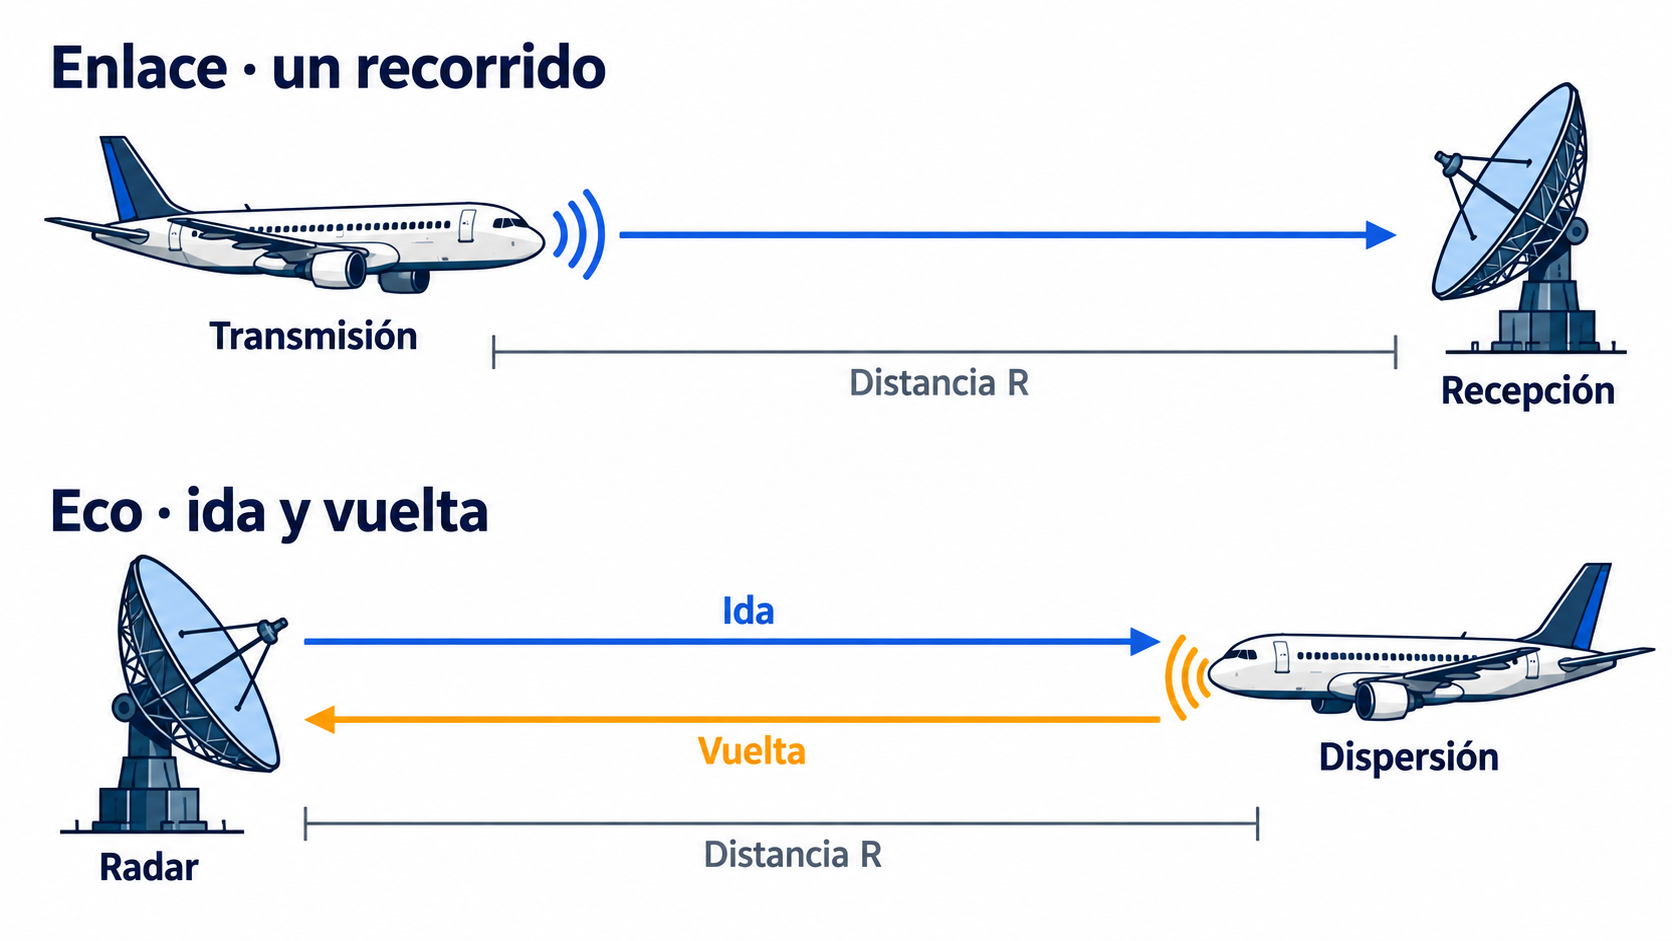

## 6 · La ecuación radar: el viaje de ida y vuelta

Para un radar monostático idealizado:
$$P_r=\frac{P_tG^2\lambda^2\sigma}{(4\pi)^3R^4L}.$$

P y R van en W y m; G y L son **factores lineales**; σ es sección radar en m²,
no área física del avión. El exponente 4 combina propagación de ida y de retorno.
Duplicar distancia divide la potencia por 16: **−12.04 dB**.

Fijamos 2.7 GHz, pérdidas de 3 dB y umbral ilustrativo −110 dBm.
El cruce de la curva con el umbral es un límite de este modelo, no alcance operacional:
no modelamos probabilidad de detección, clutter, fluctuación de σ ni procesamiento.

Eco a 60 km: -99.197 dBm
Al duplicar R: -12.041 dB


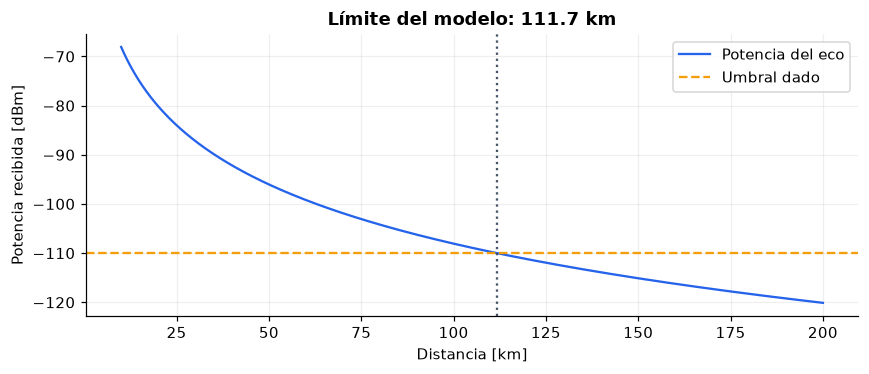

In [12]:
def radar_w(r_m, pico_kw=50, ganancia_dbi=30, sigma_m2=10):
    g = db_a_factor(ganancia_dbi)
    return pico_kw*1000 * g**2 * (C/2.7e9)**2 * sigma_m2 / ((4*np.pi)**3 * np.asarray(r_m)**4 * db_a_factor(3))

def dibujar_radar(pico_kw=50, ganancia_dbi=30, sigma_m2=10):
    dist_km = np.linspace(10, 200, 500)
    pr = w_a_dbm(radar_w(dist_km*1000, pico_kw, ganancia_dbi, sigma_m2))
    referencia_w = 1e-3 * db_a_factor(-110)
    limite_km = (radar_w(1000, pico_kw, ganancia_dbi, sigma_m2)/referencia_w)**0.25
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.plot(dist_km, pr, color="#2563EB", label="Potencia del eco")
    ax.axhline(-110, color="#F59E0B", linestyle="--", label="Umbral dado")
    ax.axvline(limite_km, color="#475569", linestyle=":")
    ax.set(xlabel="Distancia [km]", ylabel="Potencia recibida [dBm]", title=f"Límite del modelo: {limite_km:.1f} km")
    ax.grid(alpha=0.2); ax.legend(); fig.tight_layout(); plt.show()

print(f"Eco a 60 km: {w_a_dbm(radar_w(60e3)):.3f} dBm")
print(f"Al duplicar R: {10*np.log10(radar_w(120e3)/radar_w(60e3)):.3f} dB")
dibujar_radar()

**Explora:** duplica potencia de transmisión. El límite crece solo $2^{1/4}\approx1.189$ veces.
Subir 3 dB la ganancia aumenta casi 6 dB el eco porque la antena interviene dos veces.
Mantén fijos los demás parámetros al comparar.

In [13]:
try:
    control_radar = widgets.interactive(
        dibujar_radar,
        pico_kw=widgets.IntSlider(value=50, min=10, max=100, step=10, description="Pico kW", continuous_update=False),
        ganancia_dbi=widgets.IntSlider(value=30, min=20, max=40, description="G dBi", continuous_update=False),
        sigma_m2=widgets.FloatSlider(value=10, min=1, max=20, step=1, description="σ m²", continuous_update=False))
    display(control_radar)
except (ImportError, NameError):
    print("Sin widgets: ejecuta dibujar_radar(100, 30, 10).")

## 7 · Del tiempo a la observación

| Tecnología | Qué observa o recibe | Qué debes cuidar |
|---|---|---|
| PSR | Eco; $R=c\Delta t/2$ | RCS, clutter, umbral y asociación |
| SSR A/C o Mode S | Respuesta; $R=c(\Delta t-t_d)/2$ | Retardo y referencia temporal; A: código, C: altitud, S: direccionamiento/datos |
| ADS-B | Posición reportada en difusión | Fuente de a bordo, tiempo y calidad |
| MLAT | Diferencias de llegada; $\Delta d=c\Delta t$ | Sincronización, geometría y receptores válidos |

SSR interroga en 1030 MHz y recibe en 1090 MHz. ADS-B no es una medida de distancia por eco.
GNSS es una familia de sistemas; GPS es uno. ADS-C reporta por contrato, no por broadcast.
Una sola pareja TDoA define una curva, no una posición única.

Un **plot** es una detección; un **track** asocia observaciones a través del tiempo.
Fusionar exige procedencia, tiempo y calidad: no basta con promediar posiciones.

In [14]:
eco_s = 400e-6
print(f"PSR: {C*eco_s/2/1000:.1f} km")
print(f"TDoA de 100 ns: {C*100e-9:.1f} m de diferencia de camino")
print(f"Resolución sin compresión, τ=1 µs: {C*1e-6/2:.0f} m")
print(f"Alcance no ambiguo, PRF=2000 Hz: {C/(2*2000)/1000:.0f} km")
print(f"Actualización a 6 rpm: {60/6:.0f} s por giro")

PSR: 60.0 km
TDoA de 100 ns: 30.0 m de diferencia de camino
Resolución sin compresión, τ=1 µs: 150 m
Alcance no ambiguo, PRF=2000 Hz: 75 km
Actualización a 6 rpm: 10 s por giro


Resolución separa blancos; precisión describe error de medida; alcance no ambiguo evita confundir pulsos.
Son propiedades distintas. Con ancho de banda efectivo B, una aproximación de resolución es $c/(2B)$.
Una antena de 1° a 6 rpm ilumina una dirección durante $1/(6\cdot6)$ s;
a 2000 Hz caben unos 56 pulsos, distintos de los 10 s entre giros.

## 8 · Convertir y transportar información

La cadena distingue fuente → codificación → modulación → canal → demodulación → decodificación → destino.
AM cambia amplitud; FM, frecuencia; PM, fase. Sus familias digitales incluyen ASK/OOK, FSK y PSK.
**PPM cambia posición del pulso**, no solo presencia. Observa los bits 0 y 1: el pulso cambia de mitad del intervalo.

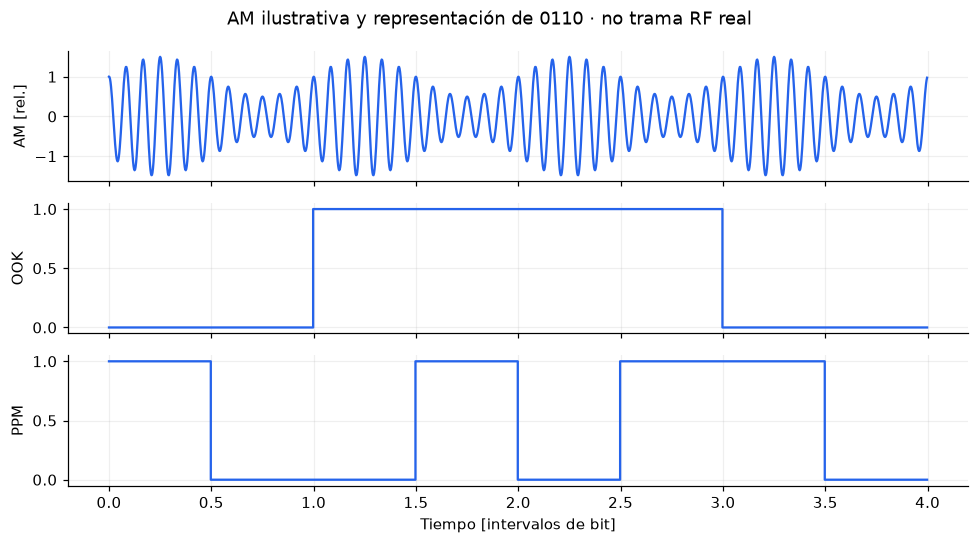

In [15]:
bits = np.array([0, 1, 1, 0])
t_bit = np.linspace(0, 4, 1600, endpoint=False)
indice = t_bit.astype(int)
fraccion = t_bit - indice
ook = bits[indice]
ppm = np.where(bits[indice] == 0, fraccion < 0.5, fraccion >= 0.5).astype(float)
portadora = np.cos(2*np.pi*12*t_bit)
am = (1+0.5*np.sin(2*np.pi*t_bit))*portadora
fig, ax = plt.subplots(3, 1, figsize=(9, 5), sharex=True)
ax[0].plot(t_bit, am, color="#2563EB"); ax[0].set_ylabel("AM [rel.]")
ax[1].step(t_bit, ook, color="#2563EB"); ax[1].set_ylabel("OOK")
ax[2].step(t_bit, ppm, color="#2563EB"); ax[2].set_ylabel("PPM")
ax[2].set_xlabel("Tiempo [intervalos de bit]")
for a in ax: a.grid(alpha=0.2)
fig.suptitle("AM ilustrativa y representación de 0110 · no trama RF real")
fig.tight_layout(); plt.show()

En banda base limitada, el modelo ideal pide $f_s>2f_{max}$ y filtro antialias previo.
Muestrear a 5 MHz una señal baseband de 1 MHz no equivale a muestrear RF de 1090 MHz.
Un ADC de N bits tiene $2^N$ niveles y paso $\Delta=FSR/2^N$.
Para un seno ideal a escala completa, $SQNR\approx6.02N+1.76$ dB. Resolución no es precisión.

Un bit admite 2 estados; un nibble, 4 bits; un byte, 8. Un símbolo puede representar varios bits:
$R_b=R_s\log_2M$. Un campo adquiere significado mediante un protocolo.

In [16]:
print("1010 binario:", int("1010", 2), "· A hexadecimal:", int("A", 16))
print(f"ADC de 10 bits y 2 V: {2/2**10*1000:.6f} mV por nivel")
print(f"112 bits a 1 Mbit/s + preámbulo dado de 8 µs: {(112/1e6+8e-6)*1e6:.0f} µs")

1010 binario: 10 · A hexadecimal: 10
ADC de 10 bits y 2 V: 1.953125 mV por nivel
112 bits a 1 Mbit/s + preámbulo dado de 8 µs: 120 µs


Los 112 bits del ejemplo **ya incluyen** 24 de paridad; no los sumes otra vez.
Un umbral produce una detección, que puede ser falsa positiva o falsa negativa.
Detectar una señal no equivale a decodificar un mensaje. Paridad/CRC comprueba integridad bajo un modelo,
no veracidad de posición ni creación de un track.

## 9 · La red también participa

$t_{serie}=L_{bits}/R_{bit/s}$; $t_{prop}=d/v$.
La latencia total suma serialización, propagación, procesamiento y cola en el recorrido definido.
Jitter es variación de retardo; aquí usaremos máximo menos mínimo.
PLR = paquetes perdidos/enviados.

La disponibilidad modelada es $A=MTBF/(MTBF+MTTR)$.
Para dos rutas independientes, cualquiera suficiente: $A_{2}=1-(1-A)^2$.
Una causa común rompe la hipótesis de independencia.

In [17]:
serie_s = 200*8/1e6
prop_s = 20e3/2e8
print(f"Latencia sin overhead: {(serie_s+prop_s+2e-3+5e-3)*1e3:.1f} ms")
retardos_ms = np.array([8, 9, 12, 8])
print(f"Jitter definido como rango: {np.ptp(retardos_ms):.0f} ms")
a = 1000/(1000+2)
print(f"Una ruta: {100*a:.6f}%; dos independientes: {100*(1-(1-a)**2):.9f}%")

Latencia sin overhead: 8.7 ms
Jitter definido como rango: 4 ms
Una ruta: 99.800399%; dos independientes: 99.999601595%


| Capa | Evidencia útil |
|---|---|
| Física | Alimentación, medio, nivel RF, conectividad |
| Enlace | Tramas y errores; MAC identifica interfaces |
| Red | Direccionamiento IP, ruta, LAN/WAN |
| Transporte | UDP: datagramas; TCP: flujo fiable ordenado, con costos de recuperación |
| Aplicación | Formato del mensaje, timestamp, origen y calidad |

El tiempo de llegada no siempre es el de observación. Un dato observado a 12:00:00 y recibido a 12:00:02
ya tiene 2 s de edad. El enlace activo no prueba que el centro reciba información vigente.

Un nodo procesa o conecta; un enlace transporta entre nodos. LAN conecta un ámbito local y WAN une ámbitos separados. Cobre, fibra y radio difieren en velocidad de propagación, pérdidas y susceptibilidad. Capacidad en bit/s no es ancho de banda físico en Hz.

## Explora más · Modelos que completan la cadena

Estas cápsulas amplían los cálculos anteriores. En cada una, identifica qué supuesto hace válida la fórmula.

### A · Circuitos y energía

Kirchhoff: la suma de corrientes en un nodo y de voltajes orientados en un lazo se conserva.
En serie se suman resistencias; en paralelo se suman conductancias. El divisor siguiente supone salida sin carga.
En RLC serie, $Z=R+j(2\pi fL-1/(2\pi fC))$.
$S=V_{rms}I_{rms}$ en VA; $P=S\,FP$ en W. Para senos ideales, $FP=\cos\phi$.

In [18]:
r1, r2 = 100, 200
print(f"Serie: {r1+r2} Ω; paralelo: {1/(1/r1+1/r2):.3f} Ω")
print(f"Divisor sin carga, 12 V: {12*r2/(r1+r2):.1f} V")
print(f"Nodo: entran 5 A, salen 2 A y {5-2} A")
print(f"Lazo orientado: 12 - 4 - 8 = {12-4-8} V")
z = 10 + 1j*(2*np.pi*1000*10e-3 - 1/(2*np.pi*1000*1e-6))
print(f"|Z| RLC: {abs(z):.3f} Ω; fase: {np.angle(z, deg=True):.2f}°")
print(f"230 V, 2 A, FP=0.8: S={230*2} VA; P={230*2*0.8} W")
print(f"1 Wh = {3600} J; voltaje 12 V = 24 J / 2 C")
paralelo_cargado = 1/(1/r2 + 1/200)
print(f"Divisor cargado con 200 Ω: {12*paralelo_cargado/(r1+paralelo_cargado):.1f} V")

Serie: 300 Ω; paralelo: 66.667 Ω
Divisor sin carga, 12 V: 8.0 V
Nodo: entran 5 A, salen 2 A y 3 A
Lazo orientado: 12 - 4 - 8 = 0 V
|Z| RLC: 96.841 Ω; fase: -84.07°
230 V, 2 A, FP=0.8: S=460 VA; P=368.0 W
1 Wh = 3600 J; voltaje 12 V = 24 J / 2 C
Divisor cargado con 200 Ω: 6.0 V


Masa es una referencia de circuito; tierra de protección cumple otra función. Un bucle de referencias puede
introducir perturbación. Un circuito abierto interrumpe el camino; un corto crea un camino de baja impedancia.
Huecos, sobretensiones, transitorios, interrupciones y ruido conducido afectan de formas distintas.
**Piensa:** ¿un fusible intacto prueba que la carga recibe tensión adecuada?

En serie circula la misma corriente; en paralelo las ramas comparten tensión. Una protección limita consecuencias, no certifica funcionamiento. Una carga conectada al divisor modifica su resistencia equivalente y su salida.

### B · Ruido, ancho de banda y decisiones

Un seno periódico, un pulso transitorio y ruido aleatorio son señales diferentes.
El siguiente ruido tiene semilla fija: la repetición permite comparar SNR.
En cascada: $F_{total}=F_1+(F_2-1)/G_1$ con factores **lineales**.
Una pérdida anterior al LNA degrada la cadena; su ubicación importa.
Shannon: $C=B\log_2(1+SNR)$, un límite de canal ideal, no capacidad de servicio garantizada.

Clasifica por ejes distintos: continuo/discreto en tiempo, analógico/digital en representación, periódico/no periódico y determinista/aleatorio. El osciloscopio muestra variación temporal; el analizador de espectro muestra componentes de frecuencia. La ganancia automática (AGC) regula nivel interno; no mejora por sí sola SNR de entrada.

In [19]:
rng = np.random.default_rng(42)
senal = np.sin(2*np.pi*50*np.arange(2000)/2000)
ruido = rng.normal(0, 0.2, len(senal))
print(f"SNR medido: {10*np.log10(np.mean(senal**2)/np.mean(ruido**2)):.2f} dB")
f_total = db_a_factor(2) + (db_a_factor(8)-1)/db_a_factor(20)
print(f"NF cascada (2 dB / 20 dB de G; luego 8 dB NF): {10*np.log10(f_total):.3f} dB")
print(f"Shannon, B=1 MHz, SNR=10 dB: {1e6*np.log2(1+db_a_factor(10))/1e6:.3f} Mbit/s")
verdad = np.array([True, False, True, False])
amplitudes = np.array([0.8, 0.7, 0.3, 0.2])
detectado = amplitudes > 0.5
print("Falsos positivos:", np.count_nonzero(detectado & ~verdad))
print("Falsos negativos:", np.count_nonzero(~detectado & verdad))

SNR medido: 10.94 dB
NF cascada (2 dB / 20 dB de G; luego 8 dB NF): 2.143 dB
Shannon, B=1 MHz, SNR=10 dB: 3.459 Mbit/s
Falsos positivos: 1
Falsos negativos: 1


### C · Medio, caminos y perturbaciones

En un medio ideal no magnético, $v\approx c/\sqrt{\epsilon_r}$.
Una línea ideal tiene $Z_0\approx\sqrt{L'/C'}$; sus parámetros son por unidad de longitud.
Un feeder con atenuación α dB/m y longitud ℓ pierde αℓ dB.

| Fenómeno | Qué cambia |
|---|---|
| Reflexión | Aparece un camino adicional |
| Absorción | Parte de la energía se disipa en el medio |
| Difracción | El campo rodea un obstáculo con pérdidas |
| Refracción | Cambia la dirección por el medio |
| Multitrayecto | Se suman copias con distintos retardos y fases |

No todos los materiales o frecuencias se comportan igual. Una copia puede reforzar o cancelar otra.
En espacio libre, duplicar distancia resta 6.02 dB en un enlace; en eco radar resta 12.04 dB.
Duplicar frecuencia suma 6.02 dB de FSPL **con ganancias fijas**.

εr=4: velocidad 1.5e+08 m/s
L'=250 nH/m, C'=100 pF/m: Z0=50.0 Ω
Feeder 20 m a 0.05 dB/m: 1.0 dB
Camino extra de 30 m: 100 ns
 118 MHz → λ=2.5424 m
1030 MHz → λ=0.2913 m
1090 MHz → λ=0.2752 m
2700 MHz → λ=0.1111 m
9000 MHz → λ=0.0333 m


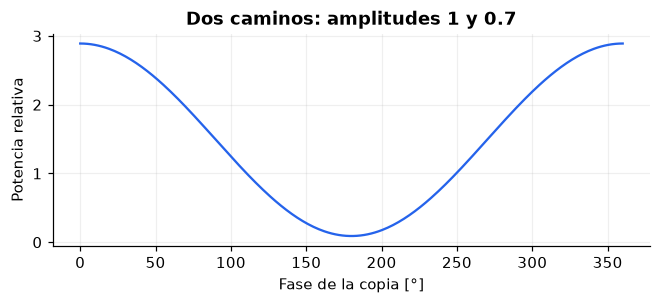

In [20]:
print(f"εr=4: velocidad {C/np.sqrt(4):.3g} m/s")
print(f"L'=250 nH/m, C'=100 pF/m: Z0={np.sqrt(250e-9/100e-12):.1f} Ω")
print(f"Feeder 20 m a 0.05 dB/m: {20*0.05:.1f} dB")
print(f"Camino extra de 30 m: {30/C*1e9:.0f} ns")
fase = np.linspace(0, 2*np.pi, 301)
potencia_rel = np.abs(1 + 0.7*np.exp(1j*fase))**2
fig, ax = plt.subplots(figsize=(7, 2.5))
ax.plot(np.rad2deg(fase), potencia_rel, color="#2563EB")
ax.set(xlabel="Fase de la copia [°]", ylabel="Potencia relativa", title="Dos caminos: amplitudes 1 y 0.7")
ax.grid(alpha=0.2); plt.show()
for mhz in [118, 1030, 1090, 2700, 9000]:
    print(f"{mhz:4d} MHz → λ={C/(mhz*1e6):.4f} m")

118 MHz se ubica en VHF; 1030/1090 MHz, en UHF según la clasificación por décadas.
2.7 GHz corresponde a S y 9 GHz a X en bandas radar usuales. Los nombres de distintas clasificaciones pueden solaparse.

Cocanal comparte canal; adyacente proviene de un canal vecino; intermodulación crea productos en una no linealidad;
autointerferencia procede del propio sistema; ruido industrial puede acoplarse al receptor.
Para SINR suma ruido e interferencia en potencia lineal, no en dBm.

In [21]:
s_w, n_w, i_w = [1e-3*db_a_factor(v) for v in [-80, -100, -90]]
print(f"SINR: {10*np.log10(s_w/(n_w+i_w)):.3f} dB")
g_lineal = 0.6 * 100
print(f"D=100 y eficiencia 60%: G={g_lineal:.0f}, {10*np.log10(g_lineal):.3f} dBi")
lam = C/2.7e9
g_parabola = 0.6*(np.pi*2/lam)**2
print(f"Parábola D=2 m, η=0.6: {10*np.log10(g_parabola):.3f} dBi")
print(f"Área efectiva: {g_parabola*lam**2/(4*np.pi):.3f} m²")
print(f"Haz aproximado 70λ/D: {70*lam/2:.3f}° (modelo de apertura dado)")
print(f"Densidad a 1 km, Pt=1 W, G=10: {1*10/(4*np.pi*1000**2):.3g} W/m²")
print(f"90° de desalineación ideal: potencia recibida cero; pérdida en dB no finita")

SINR: 9.586 dB
D=100 y eficiencia 60%: G=60, 17.782 dBi
Parábola D=2 m, η=0.6: 32.830 dBi
Área efectiva: 1.885 m²
Haz aproximado 70λ/D: 3.889° (modelo de apertura dado)
Densidad a 1 km, Pt=1 W, G=10: 7.96e-07 W/m²
90° de desalineación ideal: potencia recibida cero; pérdida en dB no finita


### D · Aliasing y geometría de localización

Un seno de 7 Hz muestreado a 10 Hz comparte muestras con un seno de −3 Hz: la información original se pierde.
El filtro previo evita que componentes fuera de banda entren al muestreo.
Con M=4 símbolos y 1000 símbolos/s, caben 2000 bits/s en el modelo sin overhead.

M=4 y Rs=1000: 2000 bit/s


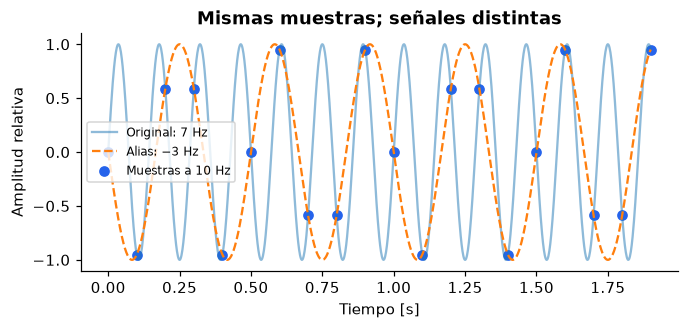

In [22]:
tiempos = np.arange(20)/10
fig, ax = plt.subplots(figsize=(7, 2.8))
continuo = np.linspace(0, 1.9, 1200)
ax.plot(continuo, np.sin(2*np.pi*7*continuo), alpha=0.5, label="Original: 7 Hz")
ax.plot(continuo, np.sin(-2*np.pi*3*continuo), linestyle="--", label="Alias: −3 Hz")
ax.scatter(tiempos, np.sin(2*np.pi*7*tiempos), color="#2563EB", label="Muestras a 10 Hz")
ax.set(xlabel="Tiempo [s]", ylabel="Amplitud relativa", title="Mismas muestras; señales distintas")
ax.legend(fontsize=8); plt.show()
print(f"M=4 y Rs=1000: {1000*np.log2(4):.0f} bit/s")

La geometría TDoA se dibuja con receptores A=(−10,0) km y B=(10,0) km.
La diferencia dA−dB=3 km corresponde a 10 µs. Todos los puntos de la curva satisfacen esa misma medición:
necesitamos más observaciones independientes y buena geometría para localizar.

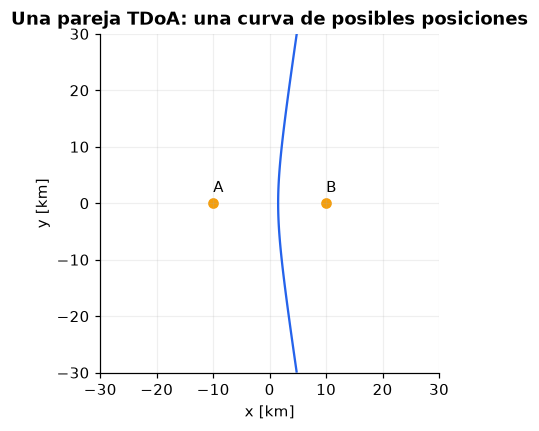

In [23]:
xx, yy = np.meshgrid(np.linspace(-30,30,401), np.linspace(-30,30,401))
diferencia_km = np.hypot(xx+10, yy) - np.hypot(xx-10, yy)
fig, ax = plt.subplots(figsize=(6, 4))
ax.contour(xx, yy, diferencia_km, levels=[3], colors=["#2563EB"])
ax.scatter([-10,10], [0,0], color="#F59E0B")
ax.annotate("A",(-10,0),xytext=(-10,2)); ax.annotate("B",(10,0),xytext=(10,2))
ax.set(xlabel="x [km]", ylabel="y [km]", title="Una pareja TDoA: una curva de posibles posiciones")
ax.set_aspect("equal"); ax.grid(alpha=0.2); plt.show()

## Misión final · Un puesto de vigilancia bajo revisión

Completa las doce hojas de cálculo de un mismo diagnóstico. Los datos pertenecen a modelos sintéticos;
las condiciones de cada hoja se declaran por separado. Usa las fórmulas anteriores y conserva SI internamente.
`mostrar()` compara números con tolerancia y deja pendientes los `None`.
Las referencias están redondeadas para lectura; calcula con toda la precisión disponible.

**Regla de cierre:** un margen favorable en RF no demuestra integridad del mensaje, sincronización o continuidad de servicio.

### Q01 · El camino eléctrico

Fuente 48 V, corriente constante 3 A, cobre con ρ=1.68e−8 Ω·m, longitud total 30 m y sección 2.5 mm². Calcula resistencia, caída, tensión en carga y pérdida.

**Salida esperada:**
```text
R [Ω]: 0.2016 | ✓
Caída [V]: 0.6048 | ✓
Carga [V]: 47.3952 | ✓
Pérdida [W]: 1.8144 | ✓
```

In [24]:
r_ohm = None
caida_v = None
carga_v = None
perdida_w = None
mostrar([r_ohm, caida_v, carga_v, perdida_w], [0.2016, 0.6048, 47.3952, 1.8144], ['R [Ω]', 'Caída [V]', 'Carga [V]', 'Pérdida [W]'])

R [Ω]: pendiente
Caída [V]: pendiente
Carga [V]: pendiente
Pérdida [W]: pendiente


### Q02 · Respaldo

Banco separado: 24 V, 100 Ah. Carga constante 120 W, fracción utilizable 0.50 y eficiencia 0.85. Calcula corriente, energía nominal y autonomía ajustada.

**Salida esperada:**
```text
I [A]: 5 | ✓
Nominal [Wh]: 2400 | ✓
Autonomía [h]: 8.5 | ✓
```

In [25]:
i_a = None
nominal_wh = None
autonomia_h = None
mostrar([i_a, nominal_wh, autonomia_h], [5, 2400, 8.5], ['I [A]', 'Nominal [Wh]', 'Autonomía [h]'])

I [A]: pendiente
Nominal [Wh]: pendiente
Autonomía [h]: pendiente


### Q03 · Pulsos

PSR: τ=1 µs, PRF=2000 Hz y pico=50 kW. Calcula período en µs, duty, potencia media y B≈1/τ en MHz.

**Salida esperada:**
```text
Tr [µs]: 500 | ✓
Duty: 0.002 | ✓
Media [W]: 100 | ✓
B aprox. [MHz]: 1 | ✓
```

In [26]:
periodo_us = None
duty = None
media_w = None
b_mhz = None
mostrar([periodo_us, duty, media_w, b_mhz], [500, 0.002, 100, 1], ['Tr [µs]', 'Duty', 'Media [W]', 'B aprox. [MHz]'])

Tr [µs]: pendiente
Duty: pendiente
Media [W]: pendiente
B aprox. [MHz]: pendiente


### Q04 · El enlace cooperativo

Enlace unidireccional: f=1090 MHz, d=200 km, Pt=50 dBm, Gt=3 dBi, Gr=8 dBi y otras pérdidas=2 dB. B=10 MHz, NF=3 dB y SNR mínimo=10 dB, a 290 K. Calcula FSPL, sensibilidad, recepción y margen.

**Salida esperada:**
```text
FSPL [dB]: 139.211 | ✓
Sensibilidad [dBm]: -91 | ✓
Pr [dBm]: -80.2109 | ✓
Margen [dB]: 10.7891 | ✓
```

In [27]:
fspl = None
sensibilidad = None
pr_dbm = None
margen_db = None
mostrar([fspl, sensibilidad, pr_dbm, margen_db], [139.21090205814076, -91, -80.21090205814076, 10.78909794185924], ['FSPL [dB]', 'Sensibilidad [dBm]', 'Pr [dBm]', 'Margen [dB]'])

FSPL [dB]: pendiente
Sensibilidad [dBm]: pendiente
Pr [dBm]: pendiente
Margen [dB]: pendiente


### Q05 · Despeje

Alturas 25 m y 10000 m. Para el mismo enlace de 200 km a 1090 MHz, calcula horizonte, Fresnel en el centro y despeje del 60%.

**Salida esperada:**
```text
Horizonte [km]: 432.6 | ✓
Fresnel [m]: 117.309 | ✓
60% [m]: 70.3856 | ✓
```

In [28]:
horizonte = None
radio = None
despeje = None
mostrar([horizonte, radio, despeje], [432.6, 117.30928, 70.385568], ['Horizonte [km]', 'Fresnel [m]', '60% [m]'])

Horizonte [km]: pendiente
Fresnel [m]: pendiente
60% [m]: pendiente


### Q06 · Adaptación y polarización

Línea ideal Z0=50 Ω y carga resistiva 75 Ω. Calcula Γ, VSWR, porcentaje reflejado y pérdida de polarización por 45° entre antenas lineales ideales.

**Salida esperada:**
```text
Γ: 0.2 | ✓
VSWR: 1.5 | ✓
Reflejada [%]: 4 | ✓
Polarización [dB]: 3.0103 | ✓
```

In [29]:
reflexion = None
vswr = None
reflejada_pct = None
polar_db = None
mostrar([reflexion, vswr, reflejada_pct, polar_db], [0.2, 1.5, 4, 3.010299956], ['Γ', 'VSWR', 'Reflejada [%]', 'Polarización [dB]'])

Γ: pendiente
VSWR: pendiente
Reflejada [%]: pendiente
Polarización [dB]: pendiente


### Q07 · Digitalización

Banda base limitada a 1 MHz, fs=5 MHz; ADC ideal de 10 bits y rango total 2 V. Calcula Ts en µs, número de niveles, paso en mV y SQNR del seno ideal a escala completa. ¿5 MHz supera 2fmax?

**Salida esperada:**
```text
Ts [µs]: 0.2 | ✓
Niveles: 1024 | ✓
Paso [mV]: 1.95312 | ✓
SQNR [dB]: 61.96 | ✓
```

In [30]:
ts_us = None
niveles = None
paso_mv = None
sqnr_db = None
mostrar([ts_us, niveles, paso_mv, sqnr_db], [0.2, 1024, 1.953125, 61.96], ['Ts [µs]', 'Niveles', 'Paso [mV]', 'SQNR [dB]'])

Ts [µs]: pendiente
Niveles: pendiente
Paso [mV]: pendiente
SQNR [dB]: pendiente


### Q08 · Duración del mensaje

Trama dada de 112 bits totales, incluyendo 24 de paridad. Rb=1 Mbit/s y preámbulo dado=8 µs. Calcula duración total.

**Salida esperada:**
```text
Mensaje [µs]: 120 | ✓
```

In [31]:
duracion_us = None
mostrar([duracion_us], [120], ['Mensaje [µs]'])

Mensaje [µs]: pendiente


### Q09 · Distancias coherentes

Los intervalos se miden entre marcas de transmisión y recepción definidas para este ejercicio. PSR: 400 µs sin retardo de blanco. SSR A/C: 403 µs con retardo dado de 3 µs. Mode S: 528 µs con retardo dado de 128 µs. Resta cada retardo antes de dividir por dos; no generalices estos valores a otros formatos.

**Salida esperada:**
```text
PSR [km]: 60 | ✓
SSR A/C [km]: 60 | ✓
Mode S [km]: 60 | ✓
```

In [32]:
psr_km = None
ac_km = None
s_km = None
mostrar([psr_km, ac_km, s_km], [60, 60, 60], ['PSR [km]', 'SSR A/C [km]', 'Mode S [km]'])

PSR [km]: pendiente
SSR A/C [km]: pendiente
Mode S [km]: pendiente


### Q10 · Diferencia de llegada

Una pareja de receptores mide TDoA=100 ns. Calcula diferencia de camino. Esto no es un error de posición.

**Salida esperada:**
```text
Diferencia [m]: 30 | ✓
```

In [33]:
camino_m = None
mostrar([camino_m], [30], ['Diferencia [m]'])

Diferencia [m]: pendiente


### Q11 · Entrega al centro

Reporte de aplicación de 200 bytes a 1 Mbit/s, fibra de 20 km con v=2e8 m/s, procesamiento=2 ms y cola=5 ms. Excluimos overhead y retransmisiones. Se pierden 10 de 1000 reportes. Calcula latencia y PLR porcentual.

**Salida esperada:**
```text
Latencia [ms]: 8.7 | ✓
PLR [%]: 1 | ✓
```

In [34]:
latencia_ms = None
plr_pct = None
mostrar([latencia_ms, plr_pct], [8.7, 1], ['Latencia [ms]', 'PLR [%]'])

Latencia [ms]: pendiente
PLR [%]: pendiente


### Q12 · Continuidad

MTBF=1000 h y MTTR=2 h. Dos rutas independientes y cualquiera suficiente. Calcula disponibilidad porcentual de una ruta y del par. La independencia es una hipótesis, no una propiedad comprobada.

**Salida esperada:**
```text
Una ruta [%]: 99.8004 | ✓
Dos rutas [%]: 99.9996 | ✓
```

In [35]:
ruta_pct = None
par_pct = None
mostrar([ruta_pct, par_pct], [99.8003992016, 99.9996015952], ['Una ruta [%]', 'Dos rutas [%]'])

Una ruta [%]: pendiente
Dos rutas [%]: pendiente


### Concluye con evidencia

Completa las frases con una opción y explica el supuesto que la sostiene:

1. Q04 da margen **[positivo / negativo]**; demuestra **[viabilidad del modelo RF / integridad total del sistema]**.
2. Q09 produce **[tres distancias iguales / tres blancos distintos]** después de corregir retardos.
3. Q10 entrega **[diferencia de camino / posición única]**.
4. Q12 depende de **[independencia / una causa común garantizada]**.

**Respuestas esperadas:** positivo; viabilidad del modelo RF; tres distancias iguales;
diferencia de camino; independencia.

Si llegan posiciones antiguas aun con buen margen RF, investiga timestamps, procesamiento y red.
Registra observación, hipótesis y evidencia: un síntoma no identifica por sí solo la causa raíz.

**Ahora puedes implementar un cálculo:** definir datos y unidades → elegir un modelo → calcular →
visualizar → verificar → explicar límites. Reinicia y ejecuta todo antes de entregar.